In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv('student_exam_performance.csv')
data.head()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [5]:
print("Dataset shape:", data.shape)
print(data.head())
print(data.info())
print(data.isnull().sum().sort_values(ascending=False).head(10))

print(data["exam_score"].describe())

Dataset shape: (100000, 44)
   student_id  age  gender education_level school_type family_income  \
0  STU_000001   20  Female     High School      Public        Middle   
1  STU_000002   17    Male     High School      Public        Middle   
2  STU_000003   18   Other   Undergraduate      Public        Middle   
3  STU_000004   20    Male     High School      Public        Middle   
4  STU_000005   16  Female     High School     Private          High   

  parent_education urban_rural  previous_exam_score  previous_gpa  ...  \
0              NaN       Rural                78.36          2.95  ...   
1              NaN    Suburban                73.40          2.89  ...   
2           Master       Urban                82.76          3.35  ...   
3      High School    Suburban                60.61          2.57  ...   
4         Bachelor    Suburban                74.79          2.84  ...   

   exam_difficulty  exam_preparation_days questions_attempted  \
0           Medium           

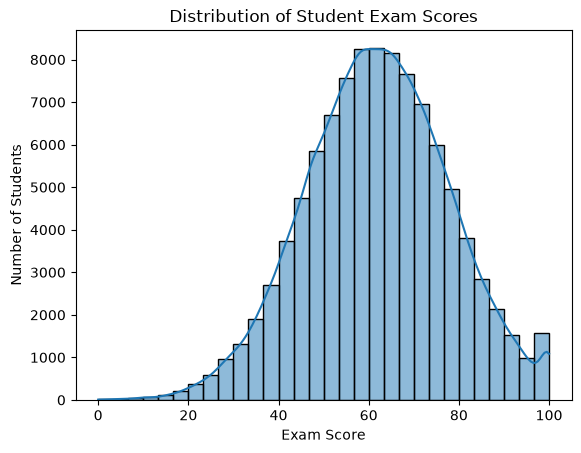

In [6]:
sns.histplot(data["exam_score"], bins=30, kde=True)
plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import joblib

df = pd.read_csv("student_exam_performance.csv")

# Target variable
y = df["exam_score"]

# Result se related columns input mein nahi lenge
drop_cols = [
    "student_id",
    "exam_score",
    "performance_grade",
    "pass_status",
    "performance_level",
    "questions_attempted",
    "questions_correct"
]

X = df.drop(columns=drop_cols)

# Numerical aur categorical columns identify karo
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns

# Missing values fill karo aur categories encode karo
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

C:\Users\sunil\AppData\Local\Temp\ipykernel_13608\1531547392.py:31: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category"]).columns


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

joblib.dump(model, "student_model.joblib")

MAE: 7.6
RMSE: 9.51
R2 Score: 0.637


['student_model.joblib']

In [10]:
import pandas as pd
import joblib

model = joblib.load("student_model.joblib")

student = pd.DataFrame([{
    "age": 18,
    "gender": "Female",
    "education_level": "High School",
    "school_type": "Public",
    "family_income": "Middle",
    "parent_education": "Graduate",
    "urban_rural": "Urban",
    "previous_exam_score": 70,
    "previous_gpa": 3.0,
    "attendance_percentage": 85,
    "assignment_completion_rate": 90,
    "class_participation": "High",
    "study_hours_per_day": 4,
    "self_study_hours": 2,
    "private_tuition": 0,
    "online_learning_hours": 2,
    "study_consistency": "Consistent",
    "study_environment": "Quiet",
    "study_method": "Mixed",
    "revision_frequency": "Weekly",
    "practice_tests_completed": 8,
    "notes_quality": "Good",
    "sleep_hours": 7,
    "sleep_quality": "Good",
    "daily_screen_time": 3,
    "physical_activity_hours": 1,
    "break_frequency": "Regular",
    "stress_level": 3,
    "motivation_level": "High",
    "internet_access": 1,
    "device_availability": "Available",
    "educational_app_usage": "Regular",
    "online_course_hours": 2,
    "exam_difficulty": "Medium",
    "exam_preparation_days": 20,
    "time_management_score": 75,
    "exam_anxiety_level": 3
}])

predicted_score = model.predict(student)[0]

print("Predicted Exam Score:", round(predicted_score, 2))

Predicted Exam Score: 75.17
